In [ ]:
!pip install tensorflow opencv-python matplotlib scikit-learn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
BASE_PATH = '/content/drive/MyDrive/CNN_project/archive'
IMAGES_PATH = os.path.join(BASE_PATH, 'images')
ANNOTATIONS_PATH = os.path.join(BASE_PATH, 'annotations')

In [ ]:
import os
import cv2
import xml.etree.ElementTree as ET

SAVE_PATH = "/content/faces"
os.makedirs(SAVE_PATH + "/mask", exist_ok=True)
os.makedirs(SAVE_PATH + "/no_mask", exist_ok=True)

count = 0

for file in os.listdir(ANNOTATIONS_PATH):
    xml_path = os.path.join(ANNOTATIONS_PATH, file)

    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
    except:
        continue

    image_file = root.find('filename').text
    img_path = os.path.join(IMAGES_PATH, image_file)

    image = cv2.imread(img_path)
    if image is None:
        continue

    for obj in root.findall('object'):
        label = obj.find('name').text

        if label == 'with_mask':
            folder = "mask"
        else:
            folder = "no_mask"

        # координаты вокруг лица
        box = obj.find('bndbox')
        xmin = int(box.find('xmin').text)
        ymin = int(box.find('ymin').text)
        xmax = int(box.find('xmax').text)
        ymax = int(box.find('ymax').text)

        face = image[ymin:ymax, xmin:xmax]

        if face.size == 0:
            continue

        face = cv2.resize(face, (224,224))

        save_file = f"{SAVE_PATH}/{folder}/{count}.jpg"
        cv2.imwrite(save_file, face)
        count += 1

print("Сохранено:", count)

Сохранено: 4072


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# аугментация
datagen = ImageDataGenerator(
    rescale=1./255, # делиv все пиксели на 255
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

train_gen = datagen.flow_from_directory(
    "/content/faces",
    target_size=(224,224),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    "/content/faces",
    target_size=(224,224),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 3258 images belonging to 2 classes.
Found 814 images belonging to 2 classes.


In [ ]:
# transfer learning
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

# заморозка слоев, т.е. старых знаний
for layer in base_model.layers:
    layer.trainable = False

x = base_model.output # наша часть
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
x = Dropout(0.3)(x) # выкл часть нейроноа
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 75s 628ms/step - accuracy: 0.8272 - loss: 1.4094 - val_accuracy: 0.8464 - val_loss: 0.7469
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 50s 494ms/step - accuracy: 0.8542 - loss: 0.6184 - val_accuracy: 0.8501 - val_loss: 0.5398
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 49s 483ms/step - accuracy: 0.8628 - loss: 0.4737 - val_accuracy: 0.8747 - val_loss: 0.4196
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 51s 497ms/step - accuracy: 0.8702 - loss: 0.4212 - val_accuracy: 0.8796 - val_loss: 0.3860
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 50s 485ms/step - accuracy: 0.8689 - loss: 0.3894 - val_accuracy: 0.8587 - val_loss: 0.3696
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 49s 483ms/step - accuracy: 0.8726 - loss: 0.3834 - val_accuracy: 0.8845 - val_loss: 0.3331
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 50s 486ms/step - accuracy: 0.8800 - loss: 0.3623 - val_accuracy: 0.8931 - val_loss: 0.3251
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 48s 476ms/step - accuracy: 0.8692 - loss: 0

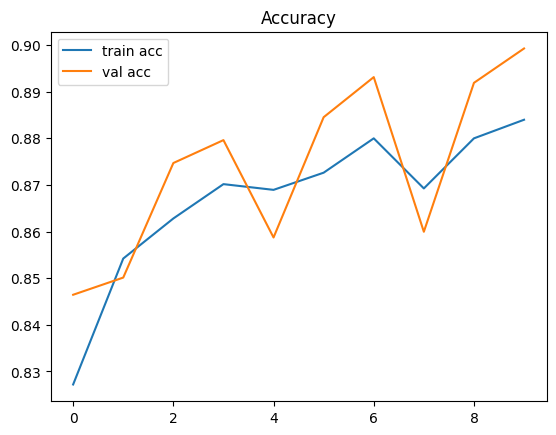

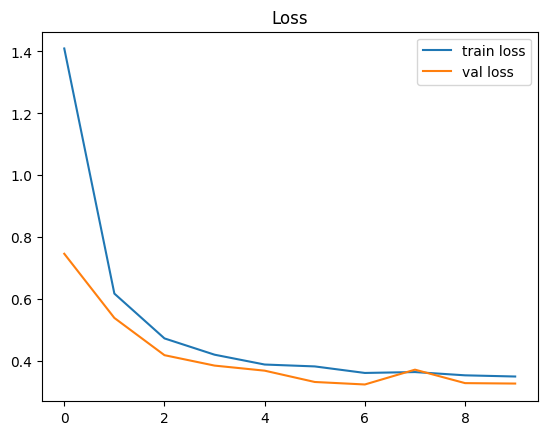

In [ ]:
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = val_gen.classes

y_pred = model.predict(val_gen)
y_pred = (y_pred > 0.5).astype(int).flatten()

print(classification_report(y_true, y_pred))

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

26/26 ━━━━━━━━━━━━━━━━━━━━ 20s 540ms/step
              precision    recall  f1-score   support

           0       0.81      0.85      0.83       646
           1       0.27      0.21      0.23       168

    accuracy                           0.72       814
   macro avg       0.54      0.53      0.53       814
weighted avg       0.69      0.72      0.71       814

Confusion Matrix:
 [[550  96]
 [133  35]]


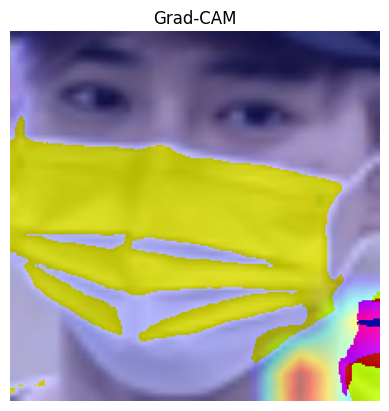

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

def get_gradcam(model, img_array, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)            # вычисляем градиенты выхода по feature map
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2)) # усредняем градиенты по ширине и высоте

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = np.maximum(heatmap, 0) / np.max(heatmap)
    return heatmap

img_path = "/content/faces/mask/0.jpg"
img = cv2.imread(img_path)
img_resized = cv2.resize(img, (224,224)) / 255.0
img_array = np.expand_dims(img_resized, axis=0) # батч размерность

last_conv_layer = "Conv_1" # последний сверт слой

heatmap = get_gradcam(model, img_array, last_conv_layer)

heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

superimposed = heatmap * 0.4 + img

plt.imshow(cv2.cvtColor(superimposed.astype('uint8'), cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM")
plt.axis('off')
plt.show()